# 👕 Cyberdyne Systems — Fashion MNIST

**Parte 2 del desafío Skynet.** Aplicamos la arquitectura seleccionada en MNIST a diez clases de prendas. Este archivo es independiente y se ejecuta de arriba abajo. Usamos TensorFlow/Keras y la arquitectura MLP con una capa oculta de 128 neuronas.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
EPOCHS, BATCH, LR = 10, 128, 0.01


## 1. Carga y exploración

Fashion MNIST contiene 60.000 imágenes de entrenamiento y 10.000 de prueba, en escala de grises y con resolución 28×28.

Train: (60000, 28, 28) uint8 | test: (10000, 28, 28)
Rango de píxeles: 0 - 255


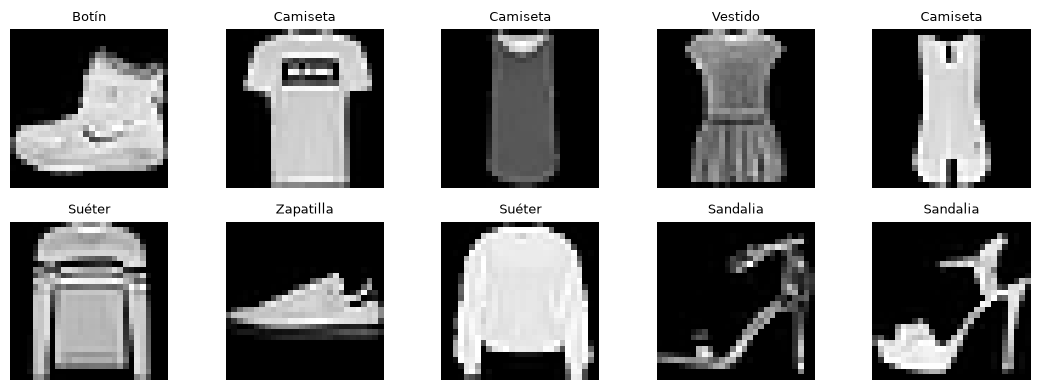

In [8]:
(xf_train, yf_train), (xf_test, yf_test) = keras.datasets.fashion_mnist.load_data()
nombres_fashion = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo", "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]
print("Train:", xf_train.shape, xf_train.dtype, "| test:", xf_test.shape)
print("Rango de píxeles:", xf_train.min(), "-", xf_train.max())
fig, axes = plt.subplots(2, 5, figsize=(11, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(xf_train[i], cmap="gray"); ax.set_title(nombres_fashion[yf_train[i]], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()


## 2. Preprocesamiento

Normalizamos los píxeles a [0, 1], aplanamos cada imagen de 28×28 a 784 valores y reservamos 10.000 imágenes de entrenamiento para validación. El conjunto de test se mantiene apartado para la evaluación final.

In [9]:
def preparar(x_tr, y_tr, x_te):
    x_tr = x_tr.astype("float32").reshape(-1, 784) / 255.0
    x_te = x_te.astype("float32").reshape(-1, 784) / 255.0
    return x_tr[:-10000], y_tr[:-10000], x_tr[-10000:], y_tr[-10000:], x_te

xf_tr, yf_tr, xf_val, yf_val, xf_te = preparar(xf_train, yf_train, xf_test)
print("train:", xf_tr.shape, "| val:", xf_val.shape, "| test:", xf_te.shape)
print("Rango normalizado:", xf_tr.min(), "-", xf_tr.max())


train: (50000, 784) | val: (10000, 784) | test: (10000, 784)
Rango normalizado: 0.0 - 1.0


## 3. Arquitectura

Usamos la arquitectura ganadora del benchmark MNIST: `Input(784) → Dense(128, Sigmoid) → Dense(10, softmax)`, entrenada con **Adam**. Tiene una capa oculta (dentro del límite de 1–2) y diez salidas para las clases de ropa.


In [12]:
def construir_modelo(activacion="sigmoid", optimizador="Adam"):
    model = keras.Sequential([
        keras.Input(shape=(784,)),
        layers.Dense(128, activation=activacion),
        layers.Dense(10, activation="softmax"),
    ])
    opt = (keras.optimizers.SGD(learning_rate=LR) if optimizador == "SGD"
           else keras.optimizers.Adam(learning_rate=LR))
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

act_gan, opt_gan = "sigmoid", "Adam"
modelo_f = construir_modelo(act_gan, opt_gan)
modelo_f.summary()


Usando: activación=sigmoid, optimizador=Adam


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Función de evaluación

Define las curvas, métricas, matriz de confusión y ejemplos de predicciones correctas e incorrectas que usaremos al final.


In [11]:
def evaluar(modelo, hist, x_te, y_te, nombres):
    # Curvas de entrenamiento y validación por epoch
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, (tr, va, titulo) in zip(ax, [("loss", "val_loss", "Loss"), ("accuracy", "val_accuracy", "Accuracy")]):
        a.plot(hist[tr], label="train")
        a.plot(hist[va], label="validación")
        a.set_title(titulo); a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    probs = modelo.predict(x_te, verbose=0)
    pred = probs.argmax(axis=1)
    acc = float((pred == y_te).mean())
    print(f"Accuracy en test: {acc:.4f}")

    cm = tf.math.confusion_matrix(y_te, pred, num_classes=10).numpy()
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(cm, cmap="Blues"); fig.colorbar(im, ax=ax)
    ax.set_xticks(range(10), nombres, rotation=45, ha="right")
    ax.set_yticks(range(10), nombres)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > cm.max()/2 else "black")
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusión (test)")
    plt.tight_layout(); plt.show()

    aciertos = np.where(pred == y_te)[0][:5]
    errores = np.where(pred != y_te)[0][:5]
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for fila, (indices, color) in enumerate([(aciertos, "green"), (errores, "red")]):
        for col, idx in enumerate(indices):
            axes[fila, col].imshow(x_te[idx].reshape(28, 28), cmap="gray")
            axes[fila, col].set_title(f"real: {nombres[y_te[idx]]}\npred: {nombres[pred[idx]]}", color=color, fontsize=8)
            axes[fila, col].axis("off")
    plt.suptitle("Fila 1: aciertos | Fila 2: errores"); plt.tight_layout(); plt.show()

    idx_errores = np.where(pred != y_te)[0]
    if len(idx_errores):
        peor = idx_errores[np.argmax(probs[idx_errores].max(axis=1))]
        top3 = np.argsort(probs[peor])[::-1][:3]
        plt.figure(figsize=(3, 3)); plt.imshow(x_te[peor].reshape(28, 28), cmap="gray"); plt.axis("off")
        plt.title(f"Error de mayor confianza\nReal: {nombres[y_te[peor]]} | Pred: {nombres[pred[peor]]}"); plt.show()
        print("Top-3 probabilidades:", [(nombres[k], round(float(probs[peor][k]), 3)) for k in top3])
        error = (nombres[y_te[peor]], nombres[pred[peor]])
    else:
        error = (None, None)
        print("No hubo errores en este conjunto de test.")

    cm_sin_diagonal = cm.copy(); np.fill_diagonal(cm_sin_diagonal, 0)
    i, j = np.unravel_index(cm_sin_diagonal.argmax(), cm_sin_diagonal.shape)
    print(f"Confusión más frecuente: real '{nombres[i]}' → predicho '{nombres[j]}' ({cm_sin_diagonal[i,j]} casos)")
    return acc, error


## 5. Entrenamiento

Registramos loss y accuracy de train y validación por epoch para revisar aprendizaje y posible sobreajuste.

In [13]:
keras.utils.set_random_seed(42)
modelo_f = construir_modelo(act_gan, opt_gan)
hist_f = modelo_f.fit(xf_tr, yf_tr, epochs=EPOCHS, batch_size=BATCH,
                      validation_data=(xf_val, yf_val), verbose=0).history
print(f"val_accuracy final: {hist_f['val_accuracy'][-1]:.4f}")


val_acc final: 0.8528


## 6. Evaluación en test

Se muestran las curvas por epoch, accuracy final, matriz de confusión, ejemplos acertados y fallidos, y el error de mayor confianza.

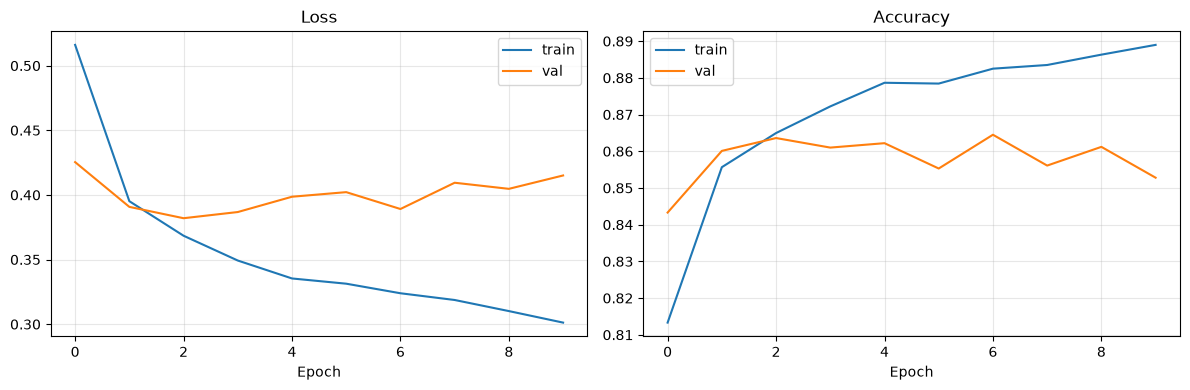

Accuracy en test: 0.8436


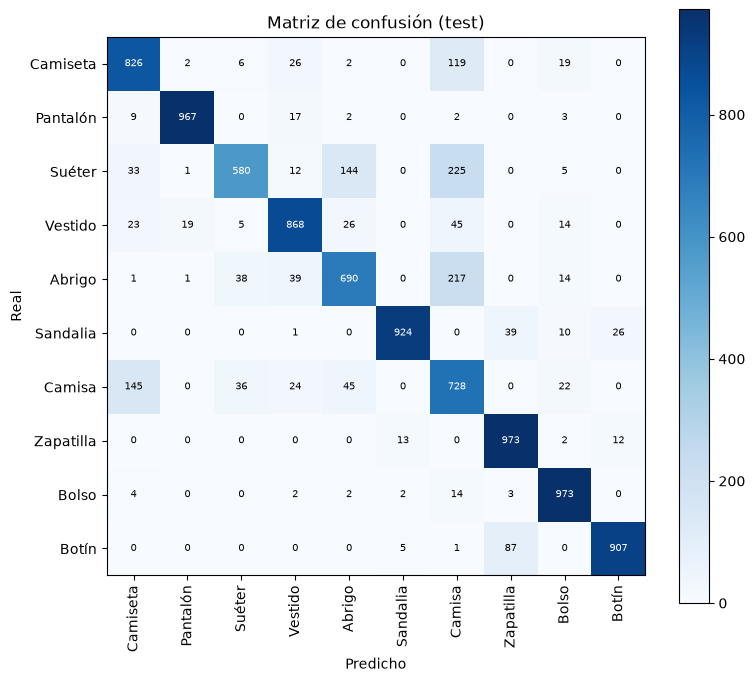

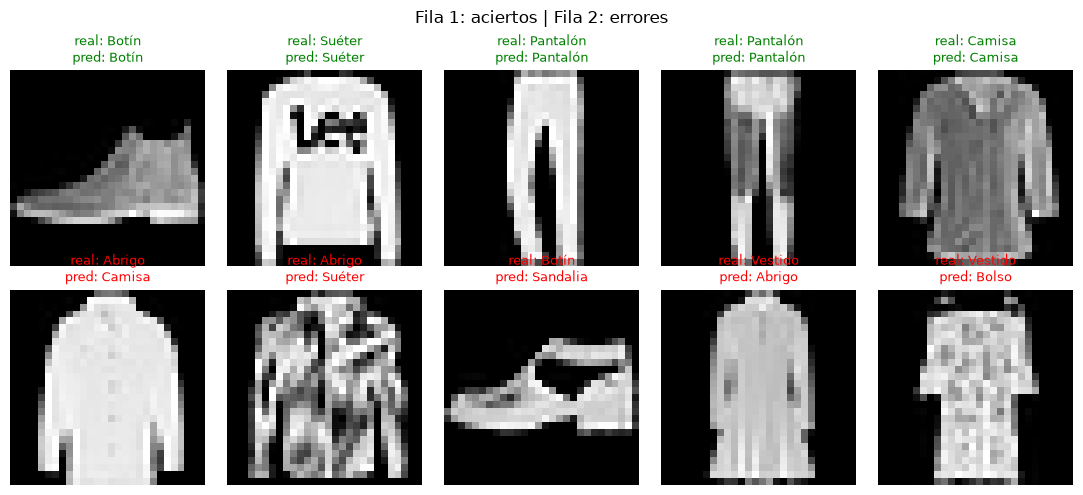

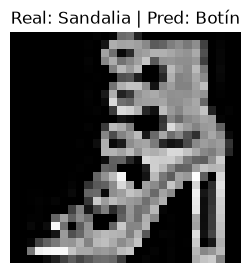

Top-3 probabilidades: [('Botín', 0.999), ('Zapatilla', 0.0), ('Sandalia', 0.0)]
Confusión más frecuente: real 'Suéter' → predicho 'Camisa' (225 veces)


In [14]:
acc_fashion, error_mayor_confianza = evaluar(modelo_f, hist_f, xf_te, yf_test, nombres_fashion)

## 7. Análisis del error y conclusiones

En esta corrida, Fashion MNIST obtuvo **84.36% de accuracy en test** (`val_accuracy=0.8528`), frente a **97.22%** de MNIST: una diferencia de **12.86 puntos porcentuales**. La matriz de confusión señala como error más frecuente **Suéter → Camisa (225 casos)**. Las siluetas y texturas de prendas diferentes pueden ser parecidas; al aplanar la imagen, la red densa además pierde la organización espacial de los píxeles.

El ejemplo de error de mayor confianza fue un **Botín** predicho como otra clase con confianza de 0.999. Esto muestra que una probabilidad alta no garantiza acierto y que algunas siluetas pueden engañar a la red. Para valorar sobreajuste, compará las curvas de train y validación: se separan si el modelo mejora en entrenamiento sin generalizar igual de bien. No se agregaron Dropout ni Early Stopping, por lo que no se midió su efecto.

**Decisión de producción:** elegiría Adam para este baseline porque fue el optimizador más rápido y eficaz en el benchmark, aunque validaría con datos de uso y otras semillas antes de desplegar. **Celda honesta:** la misma arquitectura logra resultados muy distintos según la dificultad visual del conjunto. Le tengo respeto al modelo: clasifica bien muchos ejemplos, pero la matriz y los errores de alta confianza muestran sus límites.


In [ ]:
print("MNIST (Sigmoid + Adam) — accuracy de test: 0.9722")
print(f"Fashion MNIST (Sigmoid + Adam) — accuracy de test: {acc_fashion:.4f}")
print(f"Diferencia MNIST − Fashion MNIST: {0.9722-acc_fashion:.4f}")
print(f"Error inspeccionado: real={error_mayor_confianza[0]} | predicho={error_mayor_confianza[1]}")
